# 클래스

**이 노트북에서 할 일**

1. 상품 이름과 수량을 이름으로 읽는 클래스를 정의하고, 같은 클래스로 인스턴스 두 개를 만듭니다.
2. 초기화 메서드 `__init__`, 매개변수 `self`, 메서드 호출로 인스턴스마다 값이 따로 바뀌는 것을 확인합니다.
3. 빈 목록을 클래스 본문에 둔 주문 클래스가 두 주문의 상품을 섞는 장면을 보고, 목록을 만드는 자리를 옮겨 고칩니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다.

1~5절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고릅니다.
이전 커널의 변수는 쓰지 않으므로 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

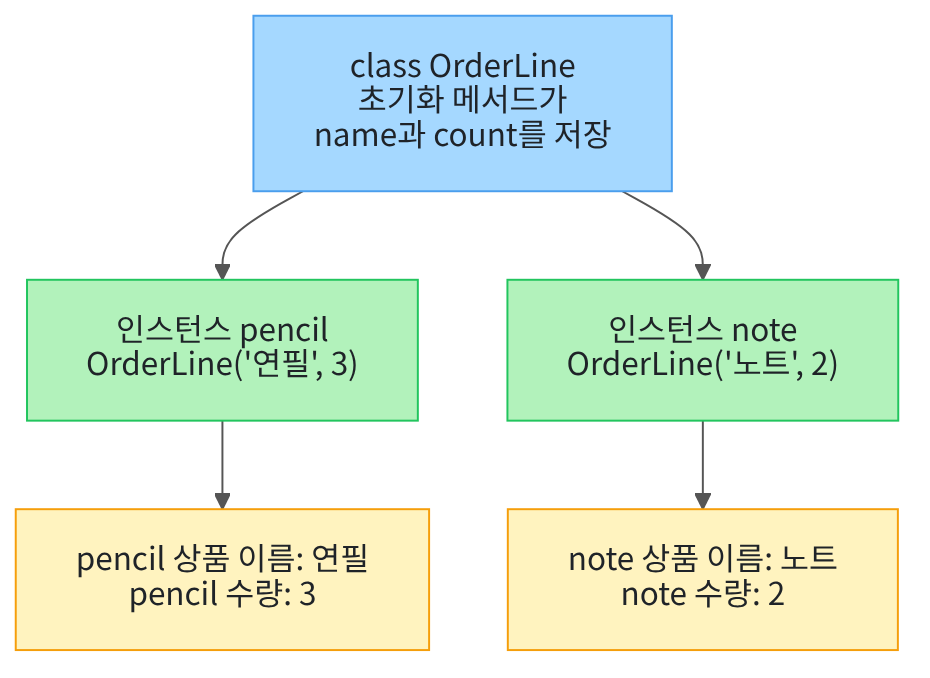

위에서 아래로 읽습니다. 파란 상자는 우리가 적은 클래스 정의, 초록 상자는 만든 인스턴스, 노란 상자는 출력입니다.

클래스 하나에서 화살표 두 개가 인스턴스 pencil과 note로 갈라집니다.
두 인스턴스는 같은 클래스로 만들었지만 상품 이름과 수량을 따로 저장합니다.

## 1. 준비

이 절은 설치할 패키지가 없고, 파일도 만들지 않습니다.
준비 셀은 5절에서 파일을 읽어 만든 주문 목록 `orders`를 새 커널에 다시 저장합니다. 주문 목록에는 (상품 이름, 수량) 튜플 두 개가 들어 있습니다.

In [1]:
# 5절에서 파일을 읽어 만든 주문 목록을 새 커널에 다시 저장합니다
orders = [("연필", 3), ("노트", 2)]
order_count = len(orders)
print("주문 목록:", orders)
print("주문 수:", order_count)

주문 목록: [('연필', 3), ('노트', 2)]
주문 수: 2


**결과 읽기** — 주문 목록은 `[('연필', 3), ('노트', 2)]`, 주문 수는 `2`입니다.
5절에서 함수 `parse_order()`로 처음 만든 주문 목록과 같습니다.

## 2. 튜플의 값을 위치 번호로 읽기

튜플은 값을 순서대로 담습니다. 그래서 첫 주문의 상품 이름은 번호 0, 수량은 번호 1로 꺼냅니다.
그런데 코드의 `[0]`과 `[1]`만 보고는 어느 쪽이 수량인지 알 수 없습니다. 5절 함수 `parse_order()`가 튜플을 만든 순서를 기억해야 합니다.

3절 「원리 더 알아보기」에서는 튜플의 수량 자리에 새 값을 넣자 `TypeError`가 났습니다. 튜플은 만든 뒤 값을 바꿀 수 없습니다.

실행 전에 예상합니다. 첫 주문 튜플의 번호 0은 연필, 번호 1은 3일 것입니다.

In [2]:
# 첫 주문 튜플에서 상품 이름과 수량을 위치 번호로 꺼냅니다
first_tuple = orders[0]
tuple_name = first_tuple[0]
tuple_count = first_tuple[1]
print("번호 0의 값:", tuple_name)
print("번호 1의 값:", tuple_count)

번호 0의 값: 연필
번호 1의 값: 3


**결과 읽기** — 번호 0의 값은 `연필`, 번호 1의 값은 `3`으로 예상과 같습니다.
출력 라벨에도 「상품 이름」, 「수량」 대신 번호만 적혔습니다. 값의 뜻을 번호가 아니라 이름으로 읽을 수 있으면 코드를 읽기 쉬워집니다.

## 3. 클래스 정의하기

클래스(class)는 함께 다니는 값과 그 값을 다루는 함수를 한 이름으로 묶은 설계입니다.
가게의 주문서 양식에 「상품 이름」 칸과 「수량」 칸이 정해져 있는 것과 같습니다.
이 셀은 상품 한 줄을 뜻하는 클래스 `OrderLine`을 정의합니다. 클래스 이름은 단어마다 첫 글자를 대문자로 적어 붙여 씁니다.

정의는 예약어 `class`, 클래스 이름, 콜론 순서로 시작합니다. 클래스에 속한 줄은 들여 씁니다.
클래스 안에 `def`로 정의한 함수를 메서드(method)라고 합니다. 3절에서 부른 `append()`도 목록의 메서드입니다.

첫 메서드 `__init__`은 초기화 메서드(initializer)입니다. 이름 앞뒤의 밑줄 두 개는 Python이 정해 둔 특별한 이름이라는 표시입니다.
클래스 이름을 함수처럼 부르면 Python이 새 값 하나를 만들고, 이 메서드를 저절로 실행합니다.
이렇게 클래스로 만든 값 하나를 인스턴스(instance)라고 합니다.

첫 매개변수 `self`에는 방금 만든 인스턴스가 들어갑니다. 줄 `self.name = name`은 인자로 받은 상품 이름을 그 인스턴스에 저장합니다.
둘째 메서드 `add_count()`는 5번 소제목에서 부릅니다.

실행 전에 예상합니다. 4절의 정의 셀처럼 출력은 없을 것입니다.

In [3]:
# 상품 이름과 수량을 함께 저장하는 클래스를 정의합니다
class OrderLine:
    # 인스턴스를 만들 때 저절로 실행되어 두 값을 인스턴스에 저장합니다
    def __init__(self, name, count):
        self.name = name
        self.count = count

    # 이 인스턴스의 수량에 extra를 더해 다시 저장합니다
    def add_count(self, extra):
        self.count = self.count + extra

**결과 읽기** — 예상대로 출력이 없습니다. 정의 셀은 클래스 이름과 메서드 두 개를 기억해 둘 뿐입니다.
메서드의 본문은 인스턴스를 만들거나 메서드를 부를 때 실행됩니다.

## 4. 인스턴스 만들기

클래스 이름 뒤에 소괄호를 붙여 부르면 인스턴스가 만들어집니다.
호출 `OrderLine("연필", 3)`의 인자는 매개변수 `self` 다음의 `name`과 `count`에 차례로 담깁니다.
매개변수 `self` 자리에는 인자를 넣지 않습니다. 이 자리에는 새 인스턴스가 저절로 들어갑니다.

속성(attribute)은 인스턴스에 저장된 이름과 값입니다. 인스턴스 이름 뒤에 점과 속성 이름을 적어 읽습니다.
5절에서 파일이 닫혔는지 읽은 `file.closed`도 속성이었습니다.

같은 클래스로 인스턴스를 두 개 만들고, 1절의 내장 함수 `type()`으로 자료형도 봅니다.

실행 전에 예상합니다. 인스턴스 pencil의 수량은 3, 인스턴스 note의 수량은 2일 것입니다.

In [4]:
# 5절 주문 튜플 두 개와 같은 값으로 인스턴스 두 개를 만듭니다
pencil = OrderLine("연필", 3)
note = OrderLine("노트", 2)
# 점 뒤에 속성 이름을 적어 인스턴스에 저장된 값을 읽습니다
print("pencil 상품 이름:", pencil.name)
print("pencil 수량:", pencil.count)
print("note 상품 이름:", note.name)
print("note 수량:", note.count)
# 1절의 type()으로 인스턴스의 자료형을 봅니다
pencil_type = type(pencil)
print("pencil의 자료형:", pencil_type)

pencil 상품 이름: 연필
pencil 수량: 3
note 상품 이름: 노트
note 수량: 2
pencil의 자료형: <class '__main__.OrderLine'>


**결과 읽기** — 출력의 수량은 `pencil 수량: 3`, `note 수량: 2`로 예상과 같습니다. 같은 클래스로 만들었지만 두 인스턴스의 값은 따로 저장됐습니다.

자료형은 `<class '__main__.OrderLine'>`입니다. 1절에서 `type()`이 보여 준 `<class 'int'>`처럼, 우리가 정의한 클래스도 자료형이 됩니다.
앞의 `__main__`은 이 노트북에서 정의한 이름이라는 표시입니다. 자세한 뜻은 7절 모듈에서 배웁니다.

## 5. 메서드 부르기

메서드는 인스턴스 이름 뒤에 점을 찍고 부릅니다. 호출 `pencil.add_count(2)`에서는 점 왼쪽의 pencil이 매개변수 `self`에 들어갑니다.
괄호 안의 2는 둘째 매개변수 `extra`에 담깁니다.

그래서 본문의 `self.count`는 `pencil.count`와 같은 값을 가리킵니다. 본문 줄은 3에 2를 더한 5를 다시 저장합니다.
3절에서 튜플의 값은 바꿀 수 없었고, 5절에서는 수량을 5로 바꾸려고 파일을 다시 썼습니다. 인스턴스의 속성은 메서드로 바꿀 수 있습니다.

실행 전에 예상합니다. 인스턴스 pencil의 수량은 5가 되고, 메서드를 부르지 않은 note의 수량은 2 그대로일 것입니다.

In [5]:
# pencil 인스턴스에만 메서드를 불러 수량에 2를 더합니다
pencil.add_count(2)
print("pencil 수량:", pencil.count)
# 메서드를 부르지 않은 note의 수량도 함께 봅니다
print("note 수량:", note.count)

pencil 수량: 5
note 수량: 2


**결과 읽기** — 출력은 `pencil 수량: 5`, `note 수량: 2`로 예상과 같습니다. 메서드는 점 왼쪽 인스턴스 pencil의 수량만 바꿨습니다.
메서드 `add_count()`에는 return 줄이 없습니다. 이 메서드는 값을 반환하지 않고, 인스턴스에 저장된 값을 바꿉니다.

## 6. 값 바꿔 보기 — 점 왼쪽 이름만 바꾸기

5번 소제목과 같은 메서드와 같은 인자 2를 씁니다. 점 왼쪽의 인스턴스 이름 하나만 pencil에서 note로 바꿉니다.
이 셀은 한 번만 실행합니다. 여러 번 실행하면 실행할 때마다 수량이 2씩 늘어납니다.

실행 전에 예상합니다. 이번에는 매개변수 `self`에 note가 들어갑니다. 그래서 note의 수량이 2에서 4가 되고, pencil의 수량은 5 그대로일 것입니다.

In [6]:
# 점 왼쪽 이름만 note로 바꿔 같은 메서드를 부릅니다
note.add_count(2)
print("pencil 수량:", pencil.count)
print("note 수량:", note.count)

pencil 수량: 5
note 수량: 4


**결과 읽기** — 출력은 `pencil 수량: 5`, `note 수량: 4`로 예상과 같습니다. 바꾼 것은 점 왼쪽 이름 하나뿐입니다.
같은 메서드를 불러도 점 왼쪽의 인스턴스가 `self`에 들어가, 그 인스턴스의 값만 바뀝니다.

## 7. Before — 빈 목록을 클래스 본문에 한 번만 적기

이번에는 고객 한 명의 주문을 클래스로 만듭니다. 주문에는 고객 이름과 상품 이름 목록이 있습니다.
메서드 `add()`는 상품 이름 하나를 목록 끝에 추가합니다.

모든 주문은 빈 목록으로 시작합니다. 그래서 빈 목록을 초기화 메서드 안이 아니라 클래스 본문에 한 번만 적었습니다.
클래스 본문에 적은 이름을 클래스 속성(class attribute)이라고 합니다. 초기화 메서드 안에서 `self`에 저장한 이름은 인스턴스 속성(instance attribute)입니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [7]:
# 고객 한 명의 주문을 저장하는 클래스를 정의합니다(빈 목록은 클래스 본문에 한 번)
class OrderBefore:
    # 모든 주문이 빈 목록으로 시작하므로 클래스 본문에 적었습니다
    items = []

    def __init__(self, customer):
        self.customer = customer

    # 상품 이름 하나를 목록 끝에 추가합니다
    def add(self, product_name):
        self.items.append(product_name)

**결과 읽기** — 출력이 없습니다. 이번 정의는 줄 `items = []`를 초기화 메서드 밖, 클래스 본문에 적었습니다.

민지와 준호의 주문을 이 클래스로 하나씩 만듭니다. 민지 주문에 노트를 추가한 뒤, 아직 아무것도 추가하지 않은 준호 주문을 출력합니다.
이어서 준호 주문에 연필을 추가합니다. 두 주문의 목록이 같은 목록인지는 3절과 4절처럼 연산자 `is`로 검사합니다.

이 셀은 한 번만 실행합니다. 여러 번 실행했다면 첫 셀부터 다시 실행합니다.

실행 전에 예상해 봅니다. 준호 주문에는 노트를 넣지 않았습니다. 노트 추가 뒤 준호 주문은 빈 목록일까요?

In [8]:
# 민지와 준호의 주문을 만들고, 민지 주문에만 노트를 추가합니다
minji_order = OrderBefore("민지")
junho_order = OrderBefore("준호")
minji_order.add("노트")
print("노트 추가 뒤 준호 주문:", junho_order.items)
# 이번에는 준호 주문에만 연필을 추가합니다
junho_order.add("연필")
is_same_list = minji_order.items is junho_order.items
print("민지 주문:", minji_order.items)
print("준호 주문:", junho_order.items)
print("같은 목록인가:", is_same_list)

노트 추가 뒤 준호 주문: ['노트']
민지 주문: ['노트', '연필']
준호 주문: ['노트', '연필']
같은 목록인가: True


**결과 읽기** — 노트 추가 뒤 준호 주문은 `['노트']`입니다. 연필을 추가한 뒤에는 민지 주문과 준호 주문이 모두 `['노트', '연필']`이고, 같은 목록인가는 `True`입니다.

오류 메시지는 나오지 않았지만, 준호 주문에 민지의 노트가 들어갔습니다. 1~5절처럼 실행이 멈추지 않아도 결과는 틀릴 수 있습니다.
4절 Before에서는 두 호출이 함수에 저장된 기본값 목록 하나를 함께 썼습니다. 이번에는 두 인스턴스가 목록 하나를 함께 썼습니다.

### 원리 더 알아보기 — 목록 items가 저장된 곳

속성 `__dict__`는 인스턴스에 저장된 속성을 딕셔너리로 보여 줍니다. 이 속성은 앞으로 쓰지 않으므로 지금은 출력만 읽습니다.
클래스 속성은 클래스 이름 뒤에 점을 찍어서도 읽을 수 있습니다.

In [9]:
# 원리 더 알아보기: 인스턴스와 클래스에 저장된 값을 각각 읽습니다
minji_attributes = minji_order.__dict__
junho_attributes = junho_order.__dict__
class_items = OrderBefore.items
print("민지 주문 인스턴스의 속성:", minji_attributes)
print("준호 주문 인스턴스의 속성:", junho_attributes)
print("클래스 OrderBefore의 items:", class_items)

민지 주문 인스턴스의 속성: {'customer': '민지'}
준호 주문 인스턴스의 속성: {'customer': '준호'}
클래스 OrderBefore의 items: ['노트', '연필']


**결과 읽기** — 민지 주문 인스턴스의 속성은 `{'customer': '민지'}`뿐이고, 이름 items가 없습니다. 준호 주문도 `{'customer': '준호'}`뿐입니다.
클래스 OrderBefore의 items는 `['노트', '연필']`입니다.
인스턴스에 없는 이름을 점 뒤에 적으면, Python은 그 인스턴스를 만든 클래스에서 같은 이름을 찾습니다.
그래서 두 주문의 `self.items`가 클래스에 저장된 목록 하나를 가리켰습니다.

## 8. After — 빈 목록을 초기화 메서드 안에서 만들기

Before 클래스와 달라진 곳은 빈 목록을 만드는 줄의 자리 하나입니다.
클래스 본문의 `items = []`를 지우고, 초기화 메서드 안에 `self.items = []`를 적었습니다. 클래스 이름은 `Order`로 바꿨습니다.

초기화 메서드는 인스턴스를 만들 때마다 실행됩니다. 그래서 주문을 하나 만들 때마다 새 빈 목록이 그 인스턴스에 저장됩니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [10]:
# 인스턴스를 만들 때마다 새 빈 목록을 저장하는 주문 클래스를 정의합니다
class Order:
    def __init__(self, customer):
        self.customer = customer
        # 초기화 메서드 안이라 인스턴스마다 새 목록이 만들어집니다
        self.items = []

    # 상품 이름 하나를 이 인스턴스의 목록 끝에 추가합니다
    def add(self, product_name):
        self.items.append(product_name)

**결과 읽기** — 출력이 없습니다. 이번 정의는 줄 `self.items = []`를 초기화 메서드 안에 적었습니다.

Before 셀과 같은 순서로 민지 주문에 노트, 준호 주문에 연필을 추가합니다. 마지막 줄의 검사 줄 `assert`로 준호 주문을 확인합니다.

실행 전에 예상합니다. 노트 추가 뒤 준호 주문은 빈 목록이고, 두 주문의 목록은 서로 다른 목록일 것입니다.

In [11]:
# 고친 클래스로 Before와 같은 순서를 실행합니다
minji_order = Order("민지")
junho_order = Order("준호")
minji_order.add("노트")
print("노트 추가 뒤 준호 주문:", junho_order.items)
junho_order.add("연필")
is_same_list = minji_order.items is junho_order.items
print("민지 주문:", minji_order.items)
print("준호 주문:", junho_order.items)
print("같은 목록인가:", is_same_list)
# 준호 주문에 연필 하나만 있지 않으면 이 줄에서 멈춥니다
assert junho_order.items == ["연필"]

노트 추가 뒤 준호 주문: []
민지 주문: ['노트']
준호 주문: ['연필']
같은 목록인가: False


**결과 읽기** — 노트 추가 뒤 준호 주문은 `[]`입니다. 민지 주문은 `['노트']`, 준호 주문은 `['연필']`이고, 같은 목록인가는 `False`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

같은 순서로 실행한 Before 클래스에서는 두 주문이 모두 ['노트', '연필']이었습니다. 달라진 곳은 빈 목록을 만드는 줄의 자리 하나입니다.

이번에 확인한 것은 목록 속성 하나입니다. 딕셔너리를 클래스 본문에 둔 경우는 이번에 실행하지 않았습니다.

## 정리

- 클래스는 함께 다니는 값과 메서드를 한 이름으로 묶은 설계입니다. 호출 `OrderLine("연필", 3)`은 초기화 메서드를 실행해 인스턴스를 만듭니다.
- 메서드를 부르면 점 왼쪽 인스턴스가 `self`에 들어갑니다. 수량에 2를 더하는 같은 메서드가 pencil만 5로, note만 4로 바꿨습니다.
- 빈 목록을 클래스 본문에 두자 두 주문이 목록 하나를 함께 써서 같은 목록인가가 True였습니다. 목록을 초기화 메서드 안에서 만들자 False가 되었습니다.

다음 절에서는 함수와 클래스를 다른 파일에 나눠 두고 `import`로 불러오는 모듈을 배웁니다. 정의 줄에 자료형을 적는 타입힌트도 함께 배웁니다.